### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
# Vocareum may use Data/ or data/ and the notebook may be in work/.
paths = [Path('coupons.csv'), Path('../data/coupons.csv'), Path('../Data/coupons.csv'),
         Path('data/coupons.csv'), Path('Data/coupons.csv'),
         Path('/voc/Data/coupons.csv'), Path('/voc/data/coupons.csv')]
found = next((p for p in paths if p.is_file()), None)
if found is None:
    raise FileNotFoundError('Cannot find coupons.csv. Check its location in Vocareum and update paths.')
data = pd.read_csv(found)
print(f'Data loaded from {found}: {data.shape[0]:,} rows × {data.shape[1]} columns')

Data loaded from coupons.csv: 12,684 rows × 26 columns


In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
print('Shape:', data.shape)
print('Column types:')
print(data.dtypes.to_string())
missing = pd.DataFrame({'missing':data.isna().sum(), 'percent':data.isna().mean().mul(100).round(2)})
display(missing[missing.missing.gt(0)].sort_values('missing',ascending=False))
print('Exact duplicate rows:',data.duplicated().sum())
print('Y distribution:')
display(data['Y'].value_counts(dropna=False))
print('Unique values in frequency columns:')
for col in ['Bar','CoffeeHouse','CarryAway','RestaurantLessThan20','Restaurant20To50']:
    print(col, sorted(data[col].dropna().astype(str).unique()))

Shape: (12684, 26)
Column types:
destination             object
passanger               object
weather                 object
temperature              int64
time                    object
coupon                  object
expiration              object
gender                  object
age                     object
maritalStatus           object
has_children             int64
education               object
occupation              object
income                  object
car                     object
Bar                     object
CoffeeHouse             object
CarryAway               object
RestaurantLessThan20    object
Restaurant20To50        object
toCoupon_GEQ5min         int64
toCoupon_GEQ15min        int64
toCoupon_GEQ25min        int64
direction_same           int64
direction_opp            int64
Y                        int64


,missing,percent
car,12576,99.15
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


Exact duplicate rows: 74
Y distribution:


Y
1    7210
0    5474
Name: count, dtype: int64

Unique values in frequency columns:
Bar ['1~3', '4~8', 'gt8', 'less1', 'never']
CoffeeHouse ['1~3', '4~8', 'gt8', 'less1', 'never']
CarryAway ['1~3', '4~8', 'gt8', 'less1', 'never']
RestaurantLessThan20 ['1~3', '4~8', 'gt8', 'less1', 'never']
Restaurant20To50 ['1~3', '4~8', 'gt8', 'less1', 'never']


3. Decide what to do about your missing data -- drop, replace, other...

In [5]:
# Keep all observations: Y is complete and the nearly empty 'car' field is not useful.
# Preserve missing frequency values as 'Unknown', avoiding assumptions about behaviour.
clean = data.drop(columns=['car'],errors='ignore').copy()
frequency_cols = ['Bar','CoffeeHouse','CarryAway','RestaurantLessThan20','Restaurant20To50']
for col in frequency_cols:
    clean[col] = clean[col].fillna('Unknown')
# Retain exact duplicates: repeated survey scenarios may represent valid observations;
# dropping them without respondent identifiers could change the estimand.
assert clean['Y'].notna().all()
assert set(clean['Y'].unique()).issubset({0,1})
print('Analysis sample:',len(clean),'rows; remaining missing cells:',clean.isna().sum().sum())

Analysis sample: 12684 rows; remaining missing cells: 0


4. What proportion of the total observations chose to accept the coupon?



In [6]:
overall = clean['Y'].mean()
print(f'Overall coupon acceptance: {overall:.2%} ({clean.Y.sum():,}/{len(clean):,})')

Overall coupon acceptance: 56.84% (7,210/12,684)


5. Use a bar plot to visualize the `coupon` column.

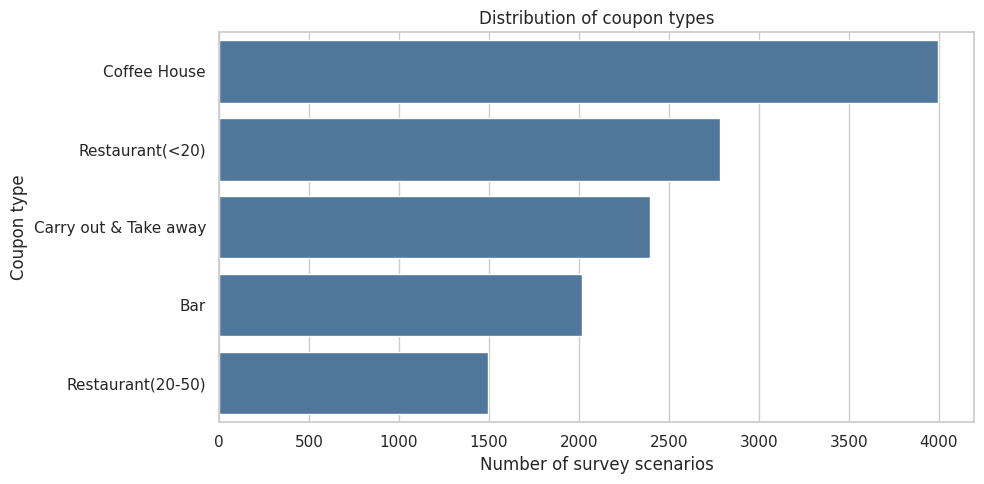

In [7]:
fig,ax=plt.subplots(figsize=(10,5))
order=clean['coupon'].value_counts().index
sns.countplot(data=clean,y='coupon',order=order,ax=ax,color='#4477AA')
ax.set(xlabel='Number of survey scenarios',ylabel='Coupon type',title='Distribution of coupon types')
plt.tight_layout();plt.show()

6. Use a histogram to visualize the temperature column.

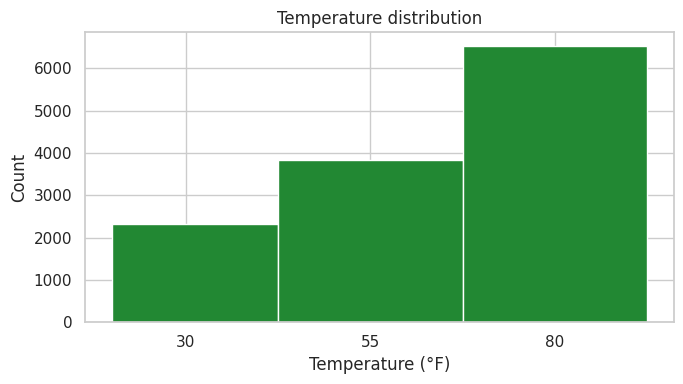

In [8]:
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(clean['temperature'],bins=[20,42.5,67.5,92.5],edgecolor='white',color='#228833')
ax.set(xticks=[30,55,80],xlabel='Temperature (°F)',ylabel='Count',title='Temperature distribution')
plt.tight_layout();plt.show()

,acceptance_rate,n,accepted
coupon,,,
Carry out & Take away,73.5%,2393,1760
Restaurant(<20),70.7%,2786,1970
Coffee House,49.9%,3996,1995
Restaurant(20-50),44.1%,1492,658
Bar,41.0%,2017,827


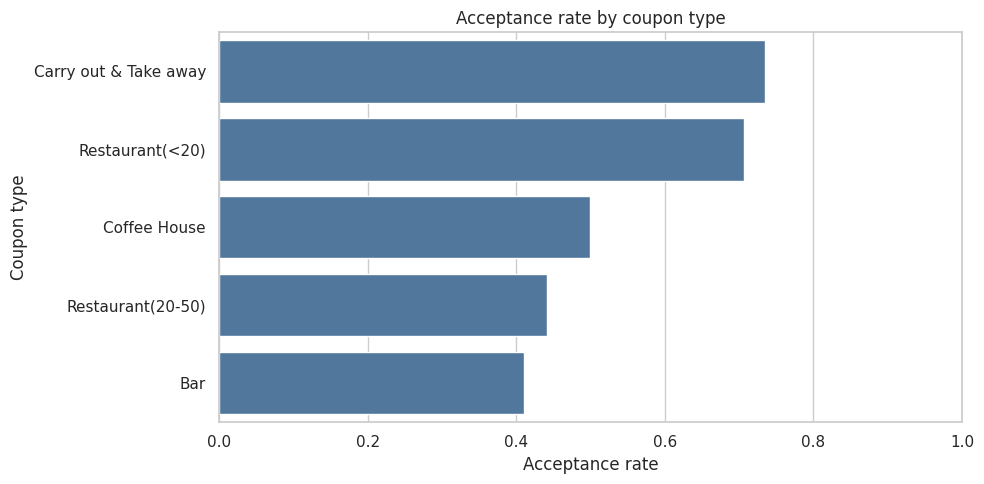

In [9]:
category = clean.groupby('coupon')['Y'].agg(['mean','count','sum']).sort_values('mean',ascending=False)
display(category.rename(columns={'mean':'acceptance_rate','count':'n','sum':'accepted'}).style.format({'acceptance_rate':'{:.1%}'}))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(x=category['mean'],y=category.index,color='#4477AA',ax=ax)
ax.set(xlim=(0,1),xlabel='Acceptance rate',ylabel='Coupon type',title='Acceptance rate by coupon type')
plt.tight_layout();plt.show()

In [10]:
print('Overall acceptance by expiration:')
display(clean.groupby('expiration')['Y'].agg(['mean','count']).rename(columns={'mean':'acceptance_rate','count':'n'}).round(3))
print('By driving destination:')
display(clean.groupby('destination')['Y'].agg(['mean','count']).rename(columns={'mean':'acceptance_rate','count':'n'}).round(3))

Overall acceptance by expiration:


,acceptance_rate,n
expiration,,
1d,0.626,7091
2h,0.496,5593


By driving destination:


,acceptance_rate,n
destination,,
Home,0.506,3237
No Urgent Place,0.634,6283
Work,0.502,3164


In [11]:
# Helper: report acceptance and sample sizes for Boolean-defined groups.
def compare_groups(frame, condition, yes_label='Condition met', no_label='Other'):
    condition = pd.Series(condition,index=frame.index).fillna(False).astype(bool)
    out = pd.DataFrame({'group':np.where(condition,yes_label,no_label),'accepted':frame.Y})
    summary=out.groupby('group')['accepted'].agg(['mean','sum','count'])
    summary.columns=['acceptance_rate','accepted','n']
    display(summary.style.format({'acceptance_rate':'{:.1%}'}))
    return summary

In [12]:
# This is observational survey data, so comparisons are associations, not causal effects.
print('All proportions use the number of nonmissing observations in their subgroup.')

All proportions use the number of nonmissing observations in their subgroup.


**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [13]:
bar=clean.loc[clean['coupon'].eq('Bar')].copy()
print('Bar coupon observations:',len(bar))
print('Bar frequency categories:',bar.Bar.value_counts().to_dict())

Bar coupon observations: 2017
Bar frequency categories: {'never': 830, 'less1': 570, '1~3': 397, '4~8': 150, 'gt8': 49, 'Unknown': 21}


2. What proportion of bar coupons were accepted?


In [14]:
print(f'Bar coupon acceptance: {bar.Y.mean():.2%} ({bar.Y.sum():,}/{len(bar):,})')

Bar coupon acceptance: 41.00% (827/2,017)


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [15]:
# Missing bar-visit frequency cannot be assigned to either comparison group.
known_bar=bar.loc[bar.Bar.ne('Unknown')].copy()
more_than_3=known_bar.Bar.isin(['4~8','gt8'])
bar_freq_summary=compare_groups(known_bar,more_than_3,'More than 3/month','3 or fewer/month')

,acceptance_rate,accepted,n
group,,,
3 or fewer/month,37.1%,666,1797
More than 3/month,76.9%,153,199


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [16]:
# Age groups 26 and older satisfy >25; 21/below21 do not.
over_25=known_bar.age.isin(['26','31','36','41','46','50plus'])
more_than_once=known_bar.Bar.isin(['1~3','4~8','gt8'])
q4=compare_groups(known_bar,more_than_once & over_25,
                  'Bar >1/month AND age >25','All others (known frequency)')

,acceptance_rate,accepted,n
group,,,
All others (known frequency),33.4%,527,1576
Bar >1/month AND age >25,69.5%,292,420


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [17]:
no_kid=known_bar.passanger.ne('Kid(s)')
not_farming=known_bar.occupation.ne('Farming Fishing & Forestry')
q5=compare_groups(known_bar,more_than_once & no_kid & not_farming,
                  'Bar >1/month, no kid passenger, not farming','All others')

,acceptance_rate,accepted,n
group,,,
All others,29.5%,426,1445
"Bar >1/month, no kid passenger, not farming",71.3%,393,551


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [18]:
# '4~8' is a grouped category; treating it as >4 is an approximation (includes exactly 4).
# The three criteria are reported separately, with a final combined OR comparison.
not_widowed=known_bar.maritalStatus.ne('Widowed')
under_30=known_bar.age.isin(['below21','21','26'])
cheap_rest_often=known_bar.RestaurantLessThan20.isin(['4~8','gt8'])
under_50k=known_bar.income.isin(['Less than $12500','$12500 - $24999',
                                 '$25000 - $37499','$37500 - $49999'])
conditions={
 'A: Bar >1/month, no kids, not widowed':more_than_once & no_kid & not_widowed,
 'B: Bar >1/month, under 30':more_than_once & under_30,
 'C: Cheap restaurant >4/month, income <50k':cheap_rest_often & under_50k,
}
for name,mask in conditions.items():
    print('\n',name)
    compare_groups(known_bar,mask,name,'Others')
combined=np.logical_or.reduce(list(conditions.values()))
print('\nCombined A OR B OR C:')
q6=compare_groups(known_bar,combined,'At least one condition','None of the conditions')


 A: Bar >1/month, no kids, not widowed


,acceptance_rate,accepted,n
group,,,
"A: Bar >1/month, no kids, not widowed",71.3%,393,551
Others,29.5%,426,1445



 B: Bar >1/month, under 30


,acceptance_rate,accepted,n
group,,,
"B: Bar >1/month, under 30",72.2%,249,345
Others,34.5%,570,1651



 C: Cheap restaurant >4/month, income <50k


,acceptance_rate,accepted,n
group,,,
"C: Cheap restaurant >4/month, income <50k",45.7%,155,339
Others,40.1%,664,1657



Combined A OR B OR C:


,acceptance_rate,accepted,n
group,,,
At least one condition,59.1%,456,771
None of the conditions,29.6%,363,1225


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [19]:
# Generate a conclusion from actual results instead of hard-coding an unverified claim.
frequent=bar_freq_summary.loc['More than 3/month','acceptance_rate']
infrequent=bar_freq_summary.loc['3 or fewer/month','acceptance_rate']
older=q4.loc['Bar >1/month AND age >25','acceptance_rate']
other=q4.loc['All others (known frequency)','acceptance_rate']
message=(f'Among respondents with reported bar-visit frequency, acceptance was '
         f'{frequent:.1%} for those visiting >3 times/month versus {infrequent:.1%} '
         f'for those visiting ≤3 times/month. Those visiting bars >1/month and aged >25 '
         f'accepted at {older:.1%}, compared with {other:.1%} among others. '
         'Hypothesis: existing bar-going habits and compatible driving circumstances '
         'are associated with higher bar-coupon acceptance. This survey cannot establish causation.')
display(Markdown('**Bar-coupon hypothesis:** '+message))

**Bar-coupon hypothesis:** Among respondents with reported bar-visit frequency, acceptance was 76.9% for those visiting >3 times/month versus 37.1% for those visiting ≤3 times/month. Those visiting bars >1/month and aged >25 accepted at 69.5%, compared with 33.4% among others. Hypothesis: existing bar-going habits and compatible driving circumstances are associated with higher bar-coupon acceptance. This survey cannot establish causation.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [20]:
# Independent investigation: Coffee House coupons.
coffee=clean.loc[clean.coupon.eq('Coffee House')].copy()
print(f'Coffee-house coupons: {len(coffee):,}; accepted: {coffee.Y.mean():.2%}')
for variable in ['time','passanger','expiration','destination','weather']:
    print('\n',variable)
    display(coffee.groupby(variable)['Y'].agg(['mean','count','sum']).sort_values('mean',ascending=False)
            .rename(columns={'mean':'rate','count':'n','sum':'accepted'}).round(3))

Coffee-house coupons: 3,996; accepted: 49.92%

 time


,rate,n,accepted
time,,,
10AM,0.641,899,576
2PM,0.548,794,435
7AM,0.446,913,407
10PM,0.424,297,126
6PM,0.413,1093,451



 passanger


,rate,n,accepted
passanger,,,
Friend(s),0.597,1228,733
Partner,0.570,305,174
Kid(s),0.483,207,100
Alone,0.438,2256,988



 expiration


,rate,n,accepted
expiration,,,
1d,0.584,1769,1033
2h,0.432,2227,962



 destination


,rate,n,accepted
destination,,,
No Urgent Place,0.581,2155,1252
Work,0.446,913,407
Home,0.362,928,336



 weather


,rate,n,accepted
weather,,,
Rainy,0.522,226,118
Sunny,0.504,3467,1746
Snowy,0.432,303,131


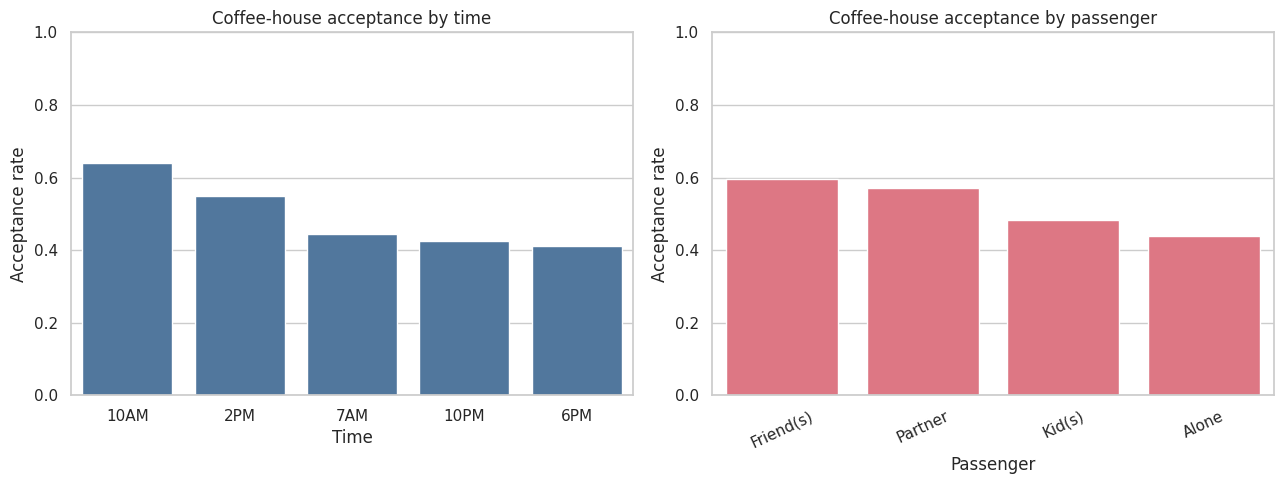

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
by_time=coffee.groupby('time')['Y'].agg(['mean','count']).sort_values('mean',ascending=False)
sns.barplot(x=by_time.index,y=by_time['mean'],ax=axes[0],color='#4477AA')
axes[0].set(title='Coffee-house acceptance by time',ylabel='Acceptance rate',xlabel='Time',ylim=(0,1))
by_pass=coffee.groupby('passanger')['Y'].agg(['mean','count']).sort_values('mean',ascending=False)
sns.barplot(x=by_pass.index,y=by_pass['mean'],ax=axes[1],color='#EE6677')
axes[1].set(title='Coffee-house acceptance by passenger',ylabel='Acceptance rate',xlabel='Passenger',ylim=(0,1))
axes[1].tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()

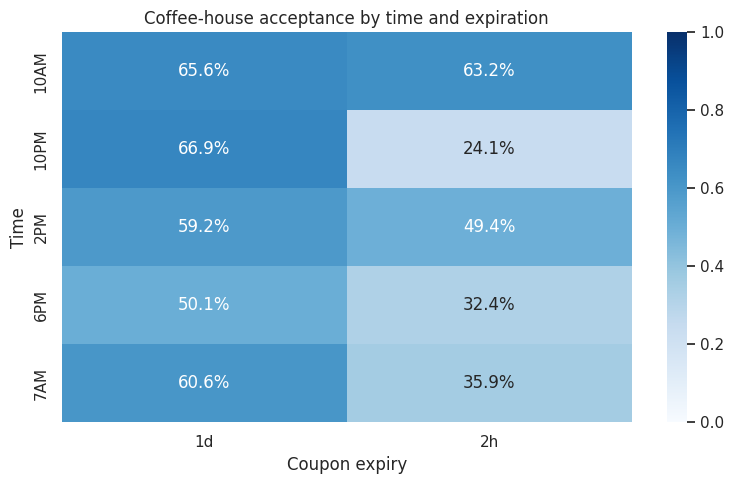

Cell sample sizes:


expiration,1d,2h
time,,
10AM,337,562
10PM,127,170
2PM,434,360
6PM,549,544
7AM,322,591


In [22]:
# Two contextual dimensions together, with sample sizes shown.
pivot=coffee.pivot_table(index='time',columns='expiration',values='Y',aggfunc='mean')
counts=coffee.pivot_table(index='time',columns='expiration',values='Y',aggfunc='size')
fig,ax=plt.subplots(figsize=(8,5))
sns.heatmap(pivot,annot=True,fmt='.1%',cmap='Blues',vmin=0,vmax=1,ax=ax)
ax.set(title='Coffee-house acceptance by time and expiration',xlabel='Coupon expiry',ylabel='Time')
plt.tight_layout();plt.show()
print('Cell sample sizes:');display(counts)

In [23]:
# Explicitly test whether proximity and expiry correlate with acceptance.
for var in ['toCoupon_GEQ15min','toCoupon_GEQ25min','expiration']:
    print('\n',var)
    display(coffee.groupby(var)['Y'].agg(['mean','count']).rename(columns={'mean':'rate','count':'n'}).round(3))
# Note: the distance flags are binary threshold indicators, not exact journey times.


 toCoupon_GEQ15min


,rate,n
toCoupon_GEQ15min,,
0,0.548,1923
1,0.454,2073



 toCoupon_GEQ25min


,rate,n
toCoupon_GEQ25min,,
0,0.512,3686
1,0.345,310



 expiration


,rate,n
expiration,,
1d,0.584,1769
2h,0.432,2227


In [24]:
# Final self-contained, data-driven report.
best_time=by_time['mean'].idxmax(); worst_time=by_time['mean'].idxmin()
best_pass=by_pass['mean'].idxmax(); worst_pass=by_pass['mean'].idxmin()
report=f"""## Findings and recommendations

**Data:** {len(clean):,} survey scenarios and {clean.shape[1]} retained columns. The largely
missing `car` column was dropped; missing visit-frequency values were retained as
`Unknown`; exact duplicate scenarios were not removed without respondent IDs.

**Overall acceptance:** {overall:.1%}. **Bar coupons:** {bar.Y.mean():.1%} acceptance
across {len(bar):,} bar-coupon scenarios. Among known-frequency respondents, bar
visitors >3/month accepted {frequent:.1%} versus {infrequent:.1%} for ≤3/month.

**Independent investigation (Coffee House):** {len(coffee):,} scenarios; acceptance
{coffee.Y.mean():.1%}. Highest observed time category: **{best_time}**
({by_time.loc[best_time,'mean']:.1%}, n={by_time.loc[best_time,'count']});
lowest: **{worst_time}** ({by_time.loc[worst_time,'mean']:.1%},
n={by_time.loc[worst_time,'count']}). Highest passenger category:
**{best_pass}** ({by_pass.loc[best_pass,'mean']:.1%}); lowest:
**{worst_pass}** ({by_pass.loc[worst_pass,'mean']:.1%}).

**Recommendation:** Tailor coupon delivery to prior venue habits and trip context;
for coffee-house coupons, test time and passenger-context segmentation in a
controlled campaign before deployment. Observed differences are descriptive,
not causal. Some subgroups may be small, and scenarios may not be independent.

**Source:** UCI In-Vehicle Coupon Recommendation dataset,
https://doi.org/10.24432/C5GS4P (CC BY 4.0).
"""
display(Markdown(report))
Path('coupon_findings.md').write_text(report,encoding='utf-8')
print('Saved coupon_findings.md')

## Findings and recommendations

**Data:** 12,684 survey scenarios and 25 retained columns. The largely
missing `car` column was dropped; missing visit-frequency values were retained as
`Unknown`; exact duplicate scenarios were not removed without respondent IDs.

**Overall acceptance:** 56.8%. **Bar coupons:** 41.0% acceptance
across 2,017 bar-coupon scenarios. Among known-frequency respondents, bar
visitors >3/month accepted 76.9% versus 37.1% for ≤3/month.

**Independent investigation (Coffee House):** 3,996 scenarios; acceptance
49.9%. Highest observed time category: **10AM**
(64.1%, n=899);
lowest: **6PM** (41.3%,
n=1093). Highest passenger category:
**Friend(s)** (59.7%); lowest:
**Alone** (43.8%).

**Recommendation:** Tailor coupon delivery to prior venue habits and trip context;
for coffee-house coupons, test time and passenger-context segmentation in a
controlled campaign before deployment. Observed differences are descriptive,
not causal. Some subgroups may be small, and scenarios may not be independent.

**Source:** UCI In-Vehicle Coupon Recommendation dataset,
https://doi.org/10.24432/C5GS4P (CC BY 4.0).


Saved coupon_findings.md
